In [1]:
import pandas as pd
import urllib.request
from zipfile import ZipFile

In [2]:
url = "https://archive.ics.uci.edu/static/public/357/occupancy+detection.zip"
urllib.request.urlretrieve(url, "occupancy.zip")

('occupancy.zip', <http.client.HTTPMessage at 0x7eb3ff5b7890>)

In [3]:
with ZipFile("occupancy.zip") as z:
    print(z.namelist())
    with z.open("datatraining.txt") as f:
        train = pd.read_csv(f)

['datatest.txt', 'datatest2.txt', 'datatraining.txt']


In [4]:
print(train.shape)
train.head()

(8143, 7)


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8143 entries, 1 to 8143
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           8143 non-null   object 
 1   Temperature    8143 non-null   float64
 2   Humidity       8143 non-null   float64
 3   Light          8143 non-null   float64
 4   CO2            8143 non-null   float64
 5   HumidityRatio  8143 non-null   float64
 6   Occupancy      8143 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 767.0+ KB


In [6]:
print("duplicate rows:", train.duplicated().sum())
train["date"] = pd.to_datetime(train["date"])
print(train["date"].min(), train["date"].max())
print("in time order:", train["date"].is_monotonic_increasing)

duplicate rows: 0
2015-02-04 17:51:00 2015-02-10 09:33:00
in time order: True


In [7]:
print(train["Occupancy"].value_counts())
print(train["Occupancy"].value_counts(normalize=True).round(3))

Occupancy
0    6414
1    1729
Name: count, dtype: int64
Occupancy
0    0.788
1    0.212
Name: proportion, dtype: float64


In [8]:
train.groupby("Occupancy")[["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]].mean().round(3)

,Temperature,Humidity,Light,CO2,HumidityRatio
Occupancy,,,,,
0,20.335,25.350,27.776,490.320,0.004
1,21.673,27.148,459.854,1037.705,0.004


In [9]:
train.groupby("Occupancy")["Light"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Occupancy,,,,,,,,
0,6414.0,27.8,89.6,0.0,0.0,0.0,0.0,1546.3
1,1729.0,459.9,42.3,31.0,433.0,454.0,477.8,744.0


In [10]:
empty = train[train["Occupancy"] == 0]
for cutoff in [0, 50, 200, 400]:
    print(cutoff, (empty["Light"] > cutoff).sum())

0 1254
50 710
200 366
400 87


In [11]:
lit_empty = train[(train["Occupancy"] == 0) & (train["Light"] > 200)]
print(lit_empty["date"].dt.floor("h").value_counts().sort_index())

date
2015-02-05 07:00:00     3
2015-02-05 08:00:00     1
2015-02-05 10:00:00     4
2015-02-05 12:00:00    15
2015-02-05 13:00:00    30
2015-02-05 14:00:00    11
2015-02-06 07:00:00     8
2015-02-06 11:00:00     4
2015-02-06 13:00:00     6
2015-02-07 09:00:00    19
2015-02-07 10:00:00    61
2015-02-07 11:00:00    59
2015-02-07 12:00:00    60
2015-02-07 13:00:00    32
2015-02-08 12:00:00    22
2015-02-08 13:00:00    25
2015-02-09 08:00:00     3
2015-02-10 08:00:00     3
Name: count, dtype: int64


In [12]:
train[["Temperature", "Humidity", "CO2", "HumidityRatio"]].corr().round(2)

,Temperature,Humidity,CO2,HumidityRatio
Temperature,1.00,-0.14,0.56,0.15
Humidity,-0.14,1.00,0.44,0.96
CO2,0.56,0.44,1.00,0.63
HumidityRatio,0.15,0.96,0.63,1.00


In [13]:
train.groupby("Occupancy")["CO2"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Occupancy,,,,,,,,
0,6414.0,490.3,152.9,412.8,437.0,446.0,464.5,1784.5
1,1729.0,1037.7,377.6,439.0,796.0,944.0,1131.2,2028.5


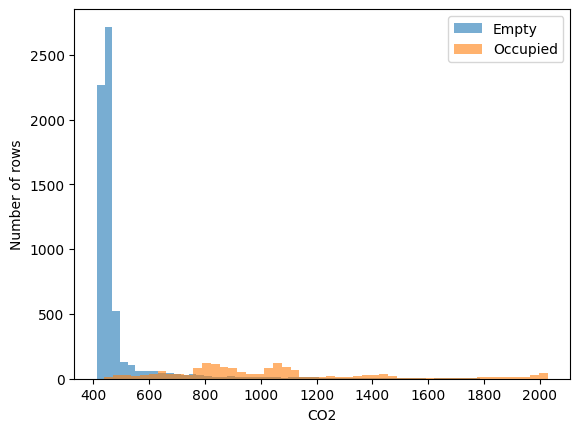

In [14]:
import matplotlib.pyplot as plt

plt.hist(train[train["Occupancy"] == 0]["CO2"], bins=50, alpha=0.6, label="Empty")
plt.hist(train[train["Occupancy"] == 1]["CO2"], bins=50, alpha=0.6, label="Occupied")
plt.xlabel("CO2")
plt.ylabel("Number of rows")
plt.legend()
plt.show()

In [15]:
with ZipFile("occupancy.zip") as z:
    with z.open("datatest.txt") as f:
        test1 = pd.read_csv(f)
    with z.open("datatest2.txt") as f:
        test2 = pd.read_csv(f)

for name, df in [("test1", test1), ("test2", test2)]:
    df["date"] = pd.to_datetime(df["date"])
    print(name, df.shape, df["date"].min(), df["date"].max())
    print(df["Occupancy"].value_counts(normalize=True).round(3).to_dict())

test1 (2665, 7) 2015-02-02 14:19:00 2015-02-04 10:43:00
{0: 0.635, 1: 0.365}
test2 (9752, 7) 2015-02-11 14:48:00 2015-02-18 09:19:00
{0: 0.79, 1: 0.21}


In [16]:
for name, df in [("test1", test1), ("test2", test2)]:
    print(name, "empty cells:", df.isna().sum().sum(), "| duplicate rows:", df.duplicated().sum(), "| in time order:", df["date"].is_monotonic_increasing)

test1 empty cells: 0 | duplicate rows: 0 | in time order: True
test2 empty cells: 0 | duplicate rows: 0 | in time order: True


In [17]:
features = ["Temperature", "Humidity", "CO2"]

X_train = train[features]
y_train = train["Occupancy"]

X_test1 = test1[features]
y_test1 = test1["Occupancy"]

X_test2 = test2[features]
y_test2 = test2["Occupancy"]

print(X_train.shape, X_test1.shape, X_test2.shape)
print(list(X_train.columns))

(8143, 3) (2665, 3) (9752, 3)
['Temperature', 'Humidity', 'CO2']


In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

base = DummyClassifier(strategy="most_frequent")
base.fit(X_train, y_train)

print("test1 baseline accuracy:", round(accuracy_score(y_test1, base.predict(X_test1)), 3))
print("test2 baseline accuracy:", round(accuracy_score(y_test2, base.predict(X_test2)), 3))

test1 baseline accuracy: 0.635
test2 baseline accuracy: 0.79


In [19]:
from sklearn.tree import DecisionTreeClassifier, export_text

tree = DecisionTreeClassifier(max_depth=3, random_state=0)
tree.fit(X_train, y_train)

print(export_text(tree, feature_names=features))

|--- CO2 <= 614.62
|   |--- Humidity <= 33.45
|   |   |--- CO2 <= 496.12
|   |   |   |--- class: 0
|   |   |--- CO2 >  496.12
|   |   |   |--- class: 0
|   |--- Humidity >  33.45
|   |   |--- class: 1
|--- CO2 >  614.62
|   |--- Temperature <= 20.78
|   |   |--- Humidity <= 32.57
|   |   |   |--- class: 1
|   |   |--- Humidity >  32.57
|   |   |   |--- class: 0
|   |--- Temperature >  20.78
|   |   |--- CO2 <= 755.17
|   |   |   |--- class: 1
|   |   |--- CO2 >  755.17
|   |   |   |--- class: 1



In [20]:
from sklearn.metrics import accuracy_score, recall_score, precision_score

for name, X, y in [("test1", X_test1, y_test1), ("test2", X_test2, y_test2)]:
    pred = tree.predict(X)
    print(name)
    print("  baseline :", round((y == 0).mean(), 3))
    print("  accuracy :", round(accuracy_score(y, pred), 3))
    print("  recall   :", round(recall_score(y, pred), 3))
    print("  precision:", round(precision_score(y, pred), 3))

test1
  baseline : 0.635
  accuracy : 0.849
  recall   : 0.933
  precision: 0.729
test2
  baseline : 0.79
  accuracy : 0.428
  recall   : 0.796
  precision: 0.24


In [21]:
cmp = pd.DataFrame({
    "train_empty": X_train[y_train == 0].median(),
    "test1_empty": X_test1[y_test1 == 0].median(),
    "test2_empty": X_test2[y_test2 == 0].median(),
})
print(cmp.round(1))

             train_empty  test1_empty  test2_empty
Temperature         20.2         20.7         20.6
Humidity            26.2         24.2         30.3
CO2                446.0        479.2        587.5


In [22]:
for name, df, X, y in [("test1", test1, X_test1, y_test1), ("test2", test2, X_test2, y_test2)]:
    pred = tree.predict(X)
    lit = df["Light"] > 200
    wasted = (y == 0) & lit
    flag = (pred == 0) & lit
    print(name)
    print("  really empty with light on:", int(wasted.sum()))
    print("  flag fired                :", int(flag.sum()))
    print("  flag fired and was right  :", int((flag & wasted).sum()))

test1
  really empty with light on: 56
  flag fired                : 74
  flag fired and was right  : 9
test2
  really empty with light on: 410
  flag fired                : 470
  flag fired and was right  : 55


In [23]:
for name, df, y in [("test1", test1, y_test1), ("test2", test2, y_test2)]:
    lit = df["Light"] > 200
    print(name, "lit rows:", int(lit.sum()), "| of those really empty:", int(((y == 0) & lit).sum()))

test1 lit rows: 1028 | of those really empty: 56
test2 lit rows: 2455 | of those really empty: 410


In [24]:
from sklearn.metrics import accuracy_score, recall_score, precision_score

for name, df, y in [("test1", test1, y_test1), ("test2", test2, y_test2)]:
    pred = (df["Light"] > 200).astype(int)
    print(name)
    print("  baseline :", round((y == 0).mean(), 3))
    print("  accuracy :", round(accuracy_score(y, pred), 3))
    print("  recall   :", round(recall_score(y, pred), 3))
    print("  precision:", round(precision_score(y, pred), 3))

test1
  baseline : 0.635
  accuracy : 0.979
  recall   : 1.0
  precision: 0.946
test2
  baseline : 0.79
  accuracy : 0.958
  recall   : 0.998
  precision: 0.833


In [25]:
features_with_light = ["Temperature", "Humidity", "CO2", "Light"]

tree_light = DecisionTreeClassifier(max_depth=3, random_state=0)
tree_light.fit(train[features_with_light], y_train)

for name, df, y in [("test1", test1, y_test1), ("test2", test2, y_test2)]:
    pred = tree_light.predict(df[features_with_light])
    print(name)
    print("  baseline :", round((y == 0).mean(), 3))
    print("  accuracy :", round(accuracy_score(y, pred), 3))
    print("  recall   :", round(recall_score(y, pred), 3))
    print("  precision:", round(precision_score(y, pred), 3))

test1
  baseline : 0.635
  accuracy : 0.978
  recall   : 0.995
  precision: 0.948
test2
  baseline : 0.79
  accuracy : 0.977
  recall   : 0.994
  precision: 0.905


In [26]:
for name, df, X, y in [("test1", test1, X_test1, y_test1), ("test2", test2, X_test2, y_test2)]:
    pred = tree.predict(X)
    flag = (pred == 0) & (df["Light"] > 300)
    print(name, "flag fired:", int(flag.sum()),
          "| flag right:", round((y[flag] == 0).mean(), 3),
          "| flag wrong:", round((y[flag] == 1).mean(), 3))

test1 flag fired: 73 | flag right: 0.123 | flag wrong: 0.877
test2 flag fired: 431 | flag right: 0.042 | flag wrong: 0.958


In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

features_with_light = ["Temperature", "Humidity", "CO2", "Light"]
tree_light = DecisionTreeClassifier(max_depth=3, random_state=0)
tree_light.fit(train[features_with_light], y_train)

rows = [
    ("Tree, no Light", tree, X_train, X_test1, X_test2),
    ("Tree, with Light", tree_light, train[features_with_light], test1[features_with_light], test2[features_with_light]),
]
for name, model, Xtr, Xt1, Xt2 in rows:
    print(name,
          "| train:", round(accuracy_score(y_train, model.predict(Xtr)), 3),
          "| test1:", round(accuracy_score(y_test1, model.predict(Xt1)), 3),
          "| test2:", round(accuracy_score(y_test2, model.predict(Xt2)), 3))

Tree, no Light | train: 0.942 | test1: 0.849 | test2: 0.428
Tree, with Light | train: 0.989 | test1: 0.978 | test2: 0.977


In [28]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

all_five = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]
tree_all = DecisionTreeClassifier(max_depth=3, random_state=0)
tree_all.fit(train[all_five], y_train)

imp = pd.DataFrame({
    "tree_all_five": pd.Series(tree_all.feature_importances_, index=all_five),
    "tree_with_light": pd.Series(tree_light.feature_importances_, index=features_with_light),
    "tree_no_light": pd.Series(tree.feature_importances_, index=features),
})
print(imp.round(3).fillna("-"))

               tree_all_five tree_with_light tree_no_light
CO2                    0.006           0.006          0.87
Humidity               0.000           0.002         0.074
HumidityRatio          0.002               -             -
Light                  0.986           0.986             -
Temperature            0.006           0.006         0.056
